# Análisis exploratorio de los datos v2 (comparación con v1)

**Objetivo:** describir la versión 2 de los datos (Entrega 3) y los cambios frente a la versión 1 (Entregas 1 y 2), antes de re-entrenar los modelos.

| | Versión 1 (`datos-v1`) | Versión 2 (`datos-v2`) |
|---|---|---|
| Vehículos | 5 (VH-01 a VH-05) | 11 (VH-01 a VH-11) |
| Contratos | 1 (piloto) | 2 activos (B y D) + contratos anteriores de los vehículos |
| Periodo | 22/05/2026 – 22/10/2026 | 01/12/2023 – 21/11/2026 |
| Viajes | 9.589 | 184.741 |

Fuente: `data/processed/` (salida de `src/pipeline_preprocesamiento.py`), descargada con `dvc pull`. Todos los datos están anonimizados: vehículos `VH-xx`, conductores `Conductor NN` y ubicaciones reemplazadas por la letra del contrato.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})
COLORES = {"Contrato D": "#164479", "Contrato B": "#F7931E", "Contrato H": "#8E8E93", "Contrato I": "#652B90",
           "Contrato G": "#19CDE3", "Traslado": "#D0D4DA"}

km = pd.read_csv("../data/processed/km_diario.csv", parse_dates=["fecha"])
viajes = pd.read_csv("../data/processed/viajes_limpios.csv", parse_dates=["fecha", "salida_dt", "llegada_dt"])
print(f"Viajes: {len(viajes):,} | vehículo-día: {len(km):,} | vehículos: {km['vehiculo'].nunique()} | "
      f"conductores: {viajes['conductor'].nunique()}")
print(f"Periodo: {km['fecha'].min():%d/%m/%Y} a {km['fecha'].max():%d/%m/%Y}")

Viajes: 184,741 | vehículo-día: 11,957 | vehículos: 11 | conductores: 259
Periodo: 01/12/2023 a 21/11/2026


## 1. Contratos en el tiempo

En la versión 2 cada viaje trae la **zona** donde ocurrió (geocerca o municipio del GPS, anonimizada como contrato). El contrato de cada día es la zona con más kilómetros; los días en tránsito entre contratos quedan como **Traslado**. Los contratos actuales son **D** (piloto, Llanos Orientales) y **B** (Tolima y Huila); **H**, **I** y **G** son contratos anteriores en los que estuvieron los vehículos de B.

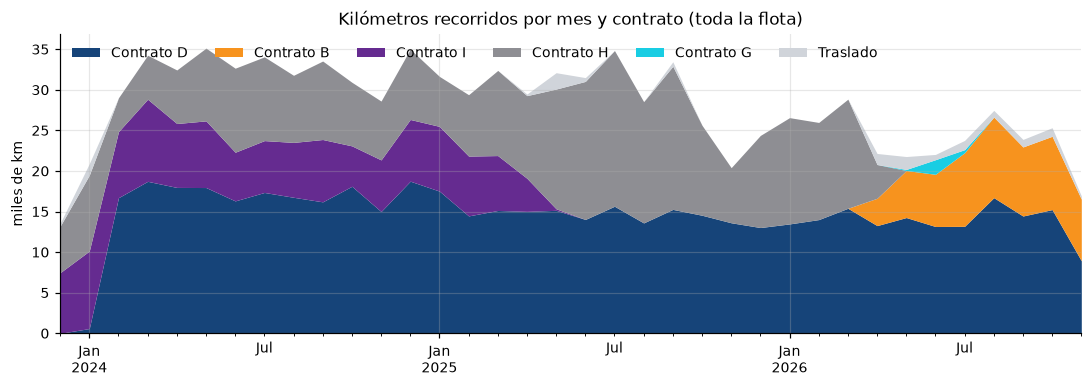

In [2]:
mensual = (km[km["con_registro"]].assign(mes_=lambda d: d["fecha"].dt.to_period("M").dt.to_timestamp())
           .groupby(["mes_", "contrato"])["km"].sum().unstack(fill_value=0) / 1000)
orden = [c for c in ["Contrato D", "Contrato B", "Contrato I", "Contrato H", "Contrato G", "Traslado"] if c in mensual]
ax = mensual[orden].plot.area(figsize=(10, 3.6), color=[COLORES[c] for c in orden], linewidth=0)
ax.set(title="Kilómetros recorridos por mes y contrato (toda la flota)", xlabel="", ylabel="miles de km")
ax.legend(ncol=6, loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

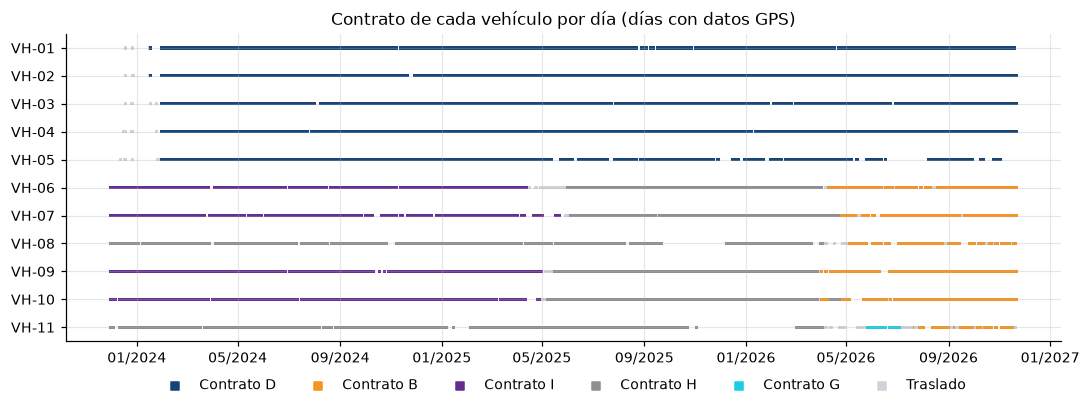

Llegada al Contrato B (primer día con contrato B en 2026):
vehiculo
VH-06    10/04/2026
VH-07    26/04/2026
VH-08    05/05/2026
VH-09    02/04/2026
VH-10    02/04/2026
VH-11    22/07/2026


In [3]:
linea = km[km["con_registro"]].copy()
vehs = sorted(linea["vehiculo"].unique(), reverse=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, v in enumerate(vehs):
    sub = linea[linea["vehiculo"] == v]
    ax.scatter(sub["fecha"], [i] * len(sub), c=sub["contrato"].map(COLORES), s=4, marker="s", linewidths=0)
ax.set_yticks(range(len(vehs)), vehs)
ax.set_title("Contrato de cada vehículo por día (días con datos GPS)")
for c in orden:
    ax.scatter([], [], c=COLORES[c], s=25, marker="s", label=c)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.tight_layout(); plt.show()

primer_b = linea[linea["contrato"] == "Contrato B"].groupby("vehiculo")["fecha"].min()
print("Llegada al Contrato B (primer día con contrato B en 2026):")
print(linea[(linea["contrato"] == "Contrato B") & (linea["fecha"] >= "2026-01-01")]
      .groupby("vehiculo")["fecha"].min().dt.strftime("%d/%m/%Y").to_string())

**Observaciones**
- Los vehículos **VH-01 a VH-05** siempre han estado en el Contrato D.
- Los vehículos **VH-06 a VH-11** pasaron por contratos anteriores (I y H) y llegaron al **Contrato B entre abril y julio de 2026**; VH-11 pasó antes por el Contrato G. Este cambio de contrato modifica su ritmo de uso, por eso el contrato se incluyó como variable del modelo.

## 2. Cobertura del GPS

Un día sin viajes puede ser un vehículo quieto (0 km) o falta de datos del GPS. El preprocesamiento considera **falta de datos** las rachas de 7 o más días sin registros; esos días no se usan para entrenar.

In [4]:
cob = km.groupby("vehiculo").agg(dias=("fecha", "size"), con_datos=("con_registro", "sum"),
                                 faltantes=("dato_faltante", "sum"), traslado=("contrato", lambda s: (s == "Traslado").sum()))
cob["% faltante"] = (100 * cob["faltantes"] / cob["dias"]).round(1)
cob

huecos = km[km["dato_faltante"]].copy()
huecos["racha"] = (huecos.groupby("vehiculo")["fecha"].diff().dt.days != 1).cumsum()
rachas = (huecos.groupby(["vehiculo", "racha"])["fecha"].agg(["min", "max", "size"])
          .query("size >= 20").reset_index(level=1, drop=True))
print("Periodos largos sin GPS (20 días o más):")
print(rachas.assign(desde=rachas["min"].dt.strftime("%d/%m/%Y"), hasta=rachas["max"].dt.strftime("%d/%m/%Y"))
      [["desde", "hasta", "size"]].rename(columns={"size": "días"}).to_string())
cob

Periodos largos sin GPS (20 días o más):
               desde       hasta  días
vehiculo                              
VH-03     28/12/2023  16/01/2024    20
VH-04     28/12/2023  24/01/2024    28
VH-05     28/12/2023  25/01/2024    29
VH-05     18/06/2026  07/08/2026    51
VH-08     23/09/2025  08/12/2025    77
VH-11     16/01/2025  04/02/2025    20
VH-11     04/11/2025  02/03/2026   119


,dias,con_datos,faltantes,traslado,% faltante
vehiculo,,,,,
VH-01,1087,887,58,47,5.3
VH-02,1087,1024,62,47,5.7
VH-03,1087,991,44,61,4.0
VH-04,1087,1017,43,61,4.0
VH-05,1087,812,186,61,17.1
VH-06,1087,916,7,58,0.6
VH-07,1087,876,43,16,4.0
VH-08,1087,813,153,37,14.1
VH-09,1087,945,11,12,1.0


## 3. Uso de los vehículos (km por día)

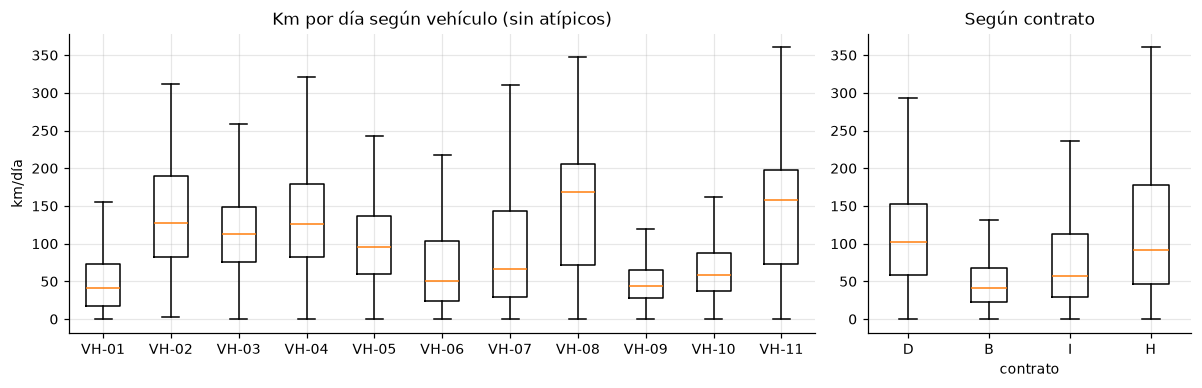

,count,mean,50%,std
contrato,,,,
Contrato B,944.0,63.3,41.0,70.8
Contrato D,4705.0,110.4,102.7,67.1
Contrato G,28.0,82.2,121.8,62.8
Contrato H,2616.0,111.8,91.6,79.6
Contrato I,1615.0,76.5,56.9,64.3


In [5]:
activos = km[km["con_registro"] & (km["contrato"] != "Traslado")]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1.3]})
orden_v = sorted(activos["vehiculo"].unique())
axs[0].boxplot([activos.loc[activos["vehiculo"] == v, "km"] for v in orden_v], tick_labels=orden_v, showfliers=False)
axs[0].set(title="Km por día según vehículo (sin atípicos)", ylabel="km/día")
contr = [c for c in ["Contrato D", "Contrato B", "Contrato I", "Contrato H"] if c in activos["contrato"].unique()]
axs[1].boxplot([activos.loc[activos["contrato"] == c, "km"] for c in contr], tick_labels=[c.replace("Contrato ", "") for c in contr],
               showfliers=False)
axs[1].set(title="Según contrato", xlabel="contrato")
plt.tight_layout(); plt.show()

activos.groupby("contrato")["km"].describe()[["count", "mean", "50%", "std"]].round(1)

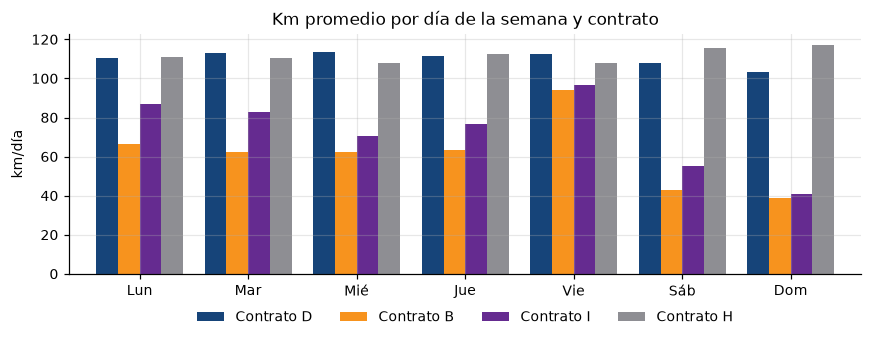

In [6]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
sem = activos.groupby(["dia_semana", "contrato"])["km"].mean().unstack()[contr]
ax = sem.set_axis(dias).plot.bar(figsize=(8, 3.2), color=[COLORES[c] for c in contr], rot=0, width=0.8)
ax.set(title="Km promedio por día de la semana y contrato", xlabel="", ylabel="km/día")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

**Observaciones**
- El uso varía mucho entre vehículos y, para un mismo vehículo, entre contratos: por eso el modelo usa el vehículo y el contrato como variables, además de los rezagos y medias móviles de los km.
- El patrón semanal depende del contrato: en B e I el uso cae con fuerza el fin de semana, mientras que en D y H es más parejo. Esto justifica las variables de calendario (`dia_semana`, `fin_de_semana`, `km_media_dia_semana`) junto con el contrato.

## 4. Variable objetivo y partición

El objetivo es `km_media_prox28`: el promedio de km por día de los **28 días siguientes**. Con él se calcula la fecha del próximo preventivo (cada 5.000 km). La partición es temporal: entrenamiento antes del **01/07/2026** y prueba desde esa fecha.

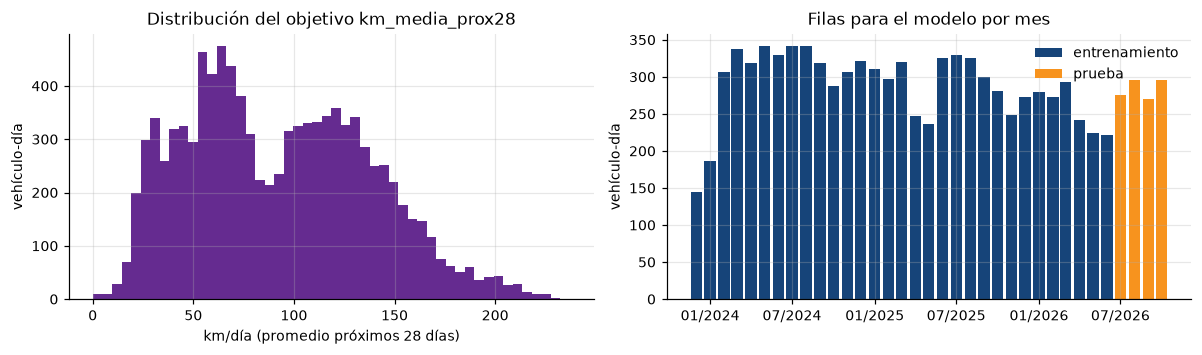

,filas,desde,hasta,vehiculos
particion,,,,
test,1138,01/07/2026,31/10/2026,11
train,8906,08/12/2023,30/06/2026,11


In [7]:
ok = km[km["apta_modelo"] & km["km_media_prox28"].notna()]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
axs[0].hist(ok["km_media_prox28"], bins=50, color="#652B90")
axs[0].set(title="Distribución del objetivo km_media_prox28", xlabel="km/día (promedio próximos 28 días)", ylabel="vehículo-día")
pm = ok.assign(mes_=ok["fecha"].dt.to_period("M").dt.to_timestamp()).groupby(["mes_", "particion"]).size().unstack(fill_value=0)
axs[1].bar(pm.index, pm.get("train", 0), width=25, color="#164479", label="entrenamiento")
axs[1].bar(pm.index, pm.get("test", 0), width=25, color="#F7931E", label="prueba")
axs[1].set(title="Filas para el modelo por mes", ylabel="vehículo-día"); axs[1].legend(frameon=False)
axs[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
plt.tight_layout(); plt.show()

part = ok.groupby("particion").agg(filas=("fecha", "size"), desde=("fecha", "min"), hasta=("fecha", "max"),
                                    vehiculos=("vehiculo", "nunique"))
part["desde"] = part["desde"].dt.strftime("%d/%m/%Y"); part["hasta"] = part["hasta"].dt.strftime("%d/%m/%Y")
part

## 5. Conclusiones

1. **Más y mejores datos:** la versión 2 multiplica por 19 los viajes y por 2 los vehículos. El conjunto de prueba pasa de **68 a 1.138 filas** y cubre los 11 vehículos ya en sus contratos actuales, lo que hace la evaluación mucho más confiable que en la Entrega 2.
2. **El contrato importa:** los vehículos del Contrato B cambiaron de contrato en 2026 y con ello su ritmo de uso; por eso se agregó `contrato` como variable y se excluyeron los días de traslado.
3. **Huecos de GPS:** hay periodos largos sin datos en algunos vehículos; el preprocesamiento los marca como faltantes en lugar de tratarlos como 0 km, para no sesgar el modelo.
4. **Mayor variabilidad:** con más vehículos y contratos el problema es más difícil; esto explica que la mejora de los modelos frente a la línea base sea menor que la observada con las 68 filas de la versión 1 (ver notebooks 01 a 07).